# 01 - Data Acquisition & Exploratory Data Analysis

**Dataset:** UCI Heart Disease (Cleveland subset, 303 patients, 13 clinical attributes + diagnosis).  
**Goal of this notebook:** obtain the data reproducibly, assess quality, clean it, and understand which attributes carry signal for predicting heart disease.

All reusable logic lives in the `heart_disease` package (`src/heart_disease`) so that the exact same cleaning code runs in the notebook, the CI pipeline and the training script.

In [1]:
%matplotlib inline
import subprocess
import sys

import pandas as pd

from heart_disease import config, eda
from heart_disease.data import clean_data, load_raw, missing_value_report

pd.set_option("display.precision", 2)

## 1. Data acquisition
`scripts/download_data.py` downloads the official archive from the UCI repository (`https://archive.ics.uci.edu/static/public/45/heart+disease.zip`), extracts the processed files into `data/raw/` and verifies the row count + SHA-256. It falls back to the legacy UCI URL and supports `--from-zip` for offline use.

In [2]:
result = subprocess.run(
    [sys.executable, str(config.PROJECT_ROOT / "scripts" / "download_data.py")],
    capture_output=True, text=True, check=True,
)
print(result.stderr or result.stdout)

2026-10-11 16:20:47,030 INFO C:\MtechBitsPilani\Sem3_MLOps_Assignment1\data\raw\processed.cleveland.data already present - skipping download (use --force to refresh)
2026-10-11 16:20:47,030 INFO processed.cleveland.data: 303 rows, sha256=a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8



In [3]:
raw = load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Data quality assessment
The raw file has no header and encodes missing values as `?`. The original target `num` is an ordinal severity score 0-4.

In [4]:
print("Missing values per column (raw):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate rows:", raw.duplicated().sum())
print("\nOriginal target 'num' distribution:")
print(raw["num"].value_counts().sort_index())
raw.describe().T

Missing values per column (raw):
ca      4
thal    2
dtype: int64

Duplicate rows: 0

Original target 'num' distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 3. Cleaning
`clean_data()` applies the following, documented rules:

| Step | Rule | Why |
|---|---|---|
| Type coercion | every column to numeric, garbage -> NaN | robust to malformed inputs |
| Range validation | e.g. cholesterol outside 80-700 mg/dl -> NaN | other UCI sites encode *unknown* as `0` |
| Category validation | unknown codes (e.g. `cp=9`) -> NaN | protects one-hot encoding |
| Target | `num > 0` -> 1 (disease), else 0 | binary problem statement; severity classes 1-4 are too small |
| Duplicates / missing target | dropped | |

Remaining missing values (`ca`, `thal`) are **not** imputed here. They are imputed *inside* the sklearn pipeline, fit on training folds only, which avoids leakage and guarantees the same treatment at inference time.

In [5]:
clean = clean_data(raw)
print(clean.shape)
display(missing_value_report(clean))
clean.head()

(303, 14)


,missing,pct
ca,4,1.32
thal,2,0.66


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


## 4. Class balance

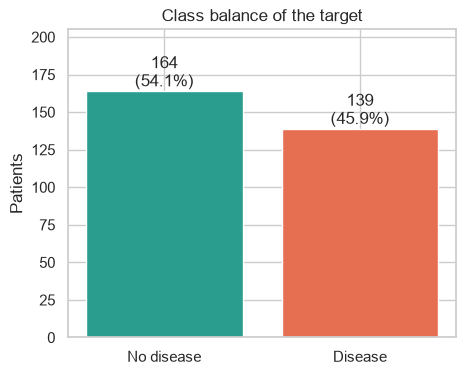

In [6]:
eda.plot_class_balance(clean);

The classes are close to balanced (~54 % / 46 %), so no resampling is needed. We still use **stratified** splits and report ROC-AUC, precision and recall rather than accuracy alone.

## 5. Numeric features

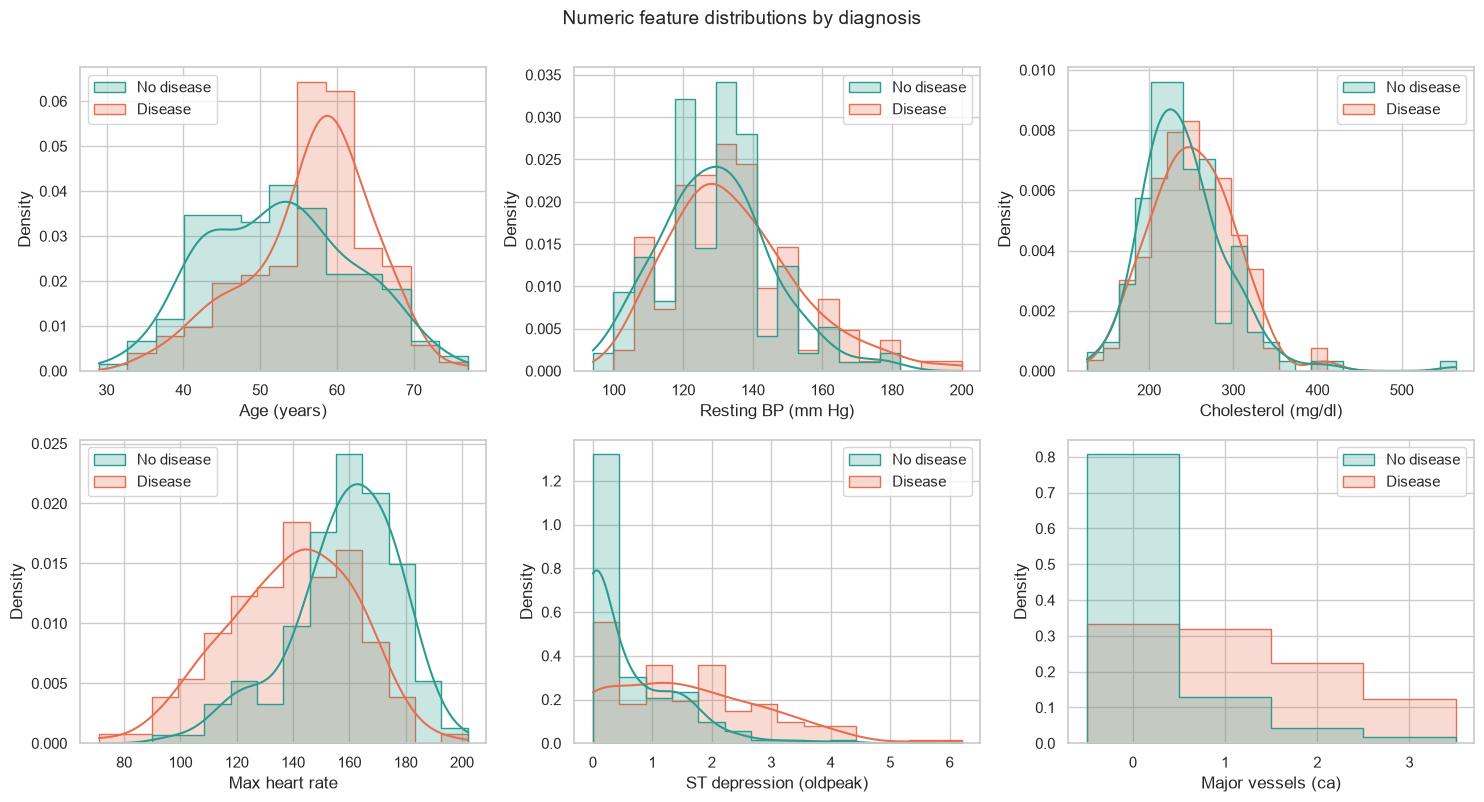

In [7]:
eda.plot_numeric_distributions(clean);

In [8]:
clean.groupby(config.TARGET)[config.NUMERIC_FEATURES].median().rename(index=eda.TARGET_LABELS)

,age,trestbps,chol,thalach,oldpeak,ca
target,,,,,,
No disease,52.0,130.0,234.5,161.0,0.2,0.0
Disease,58.0,130.0,249.0,142.0,1.4,1.0


## 6. Categorical / binary features - disease rate per category

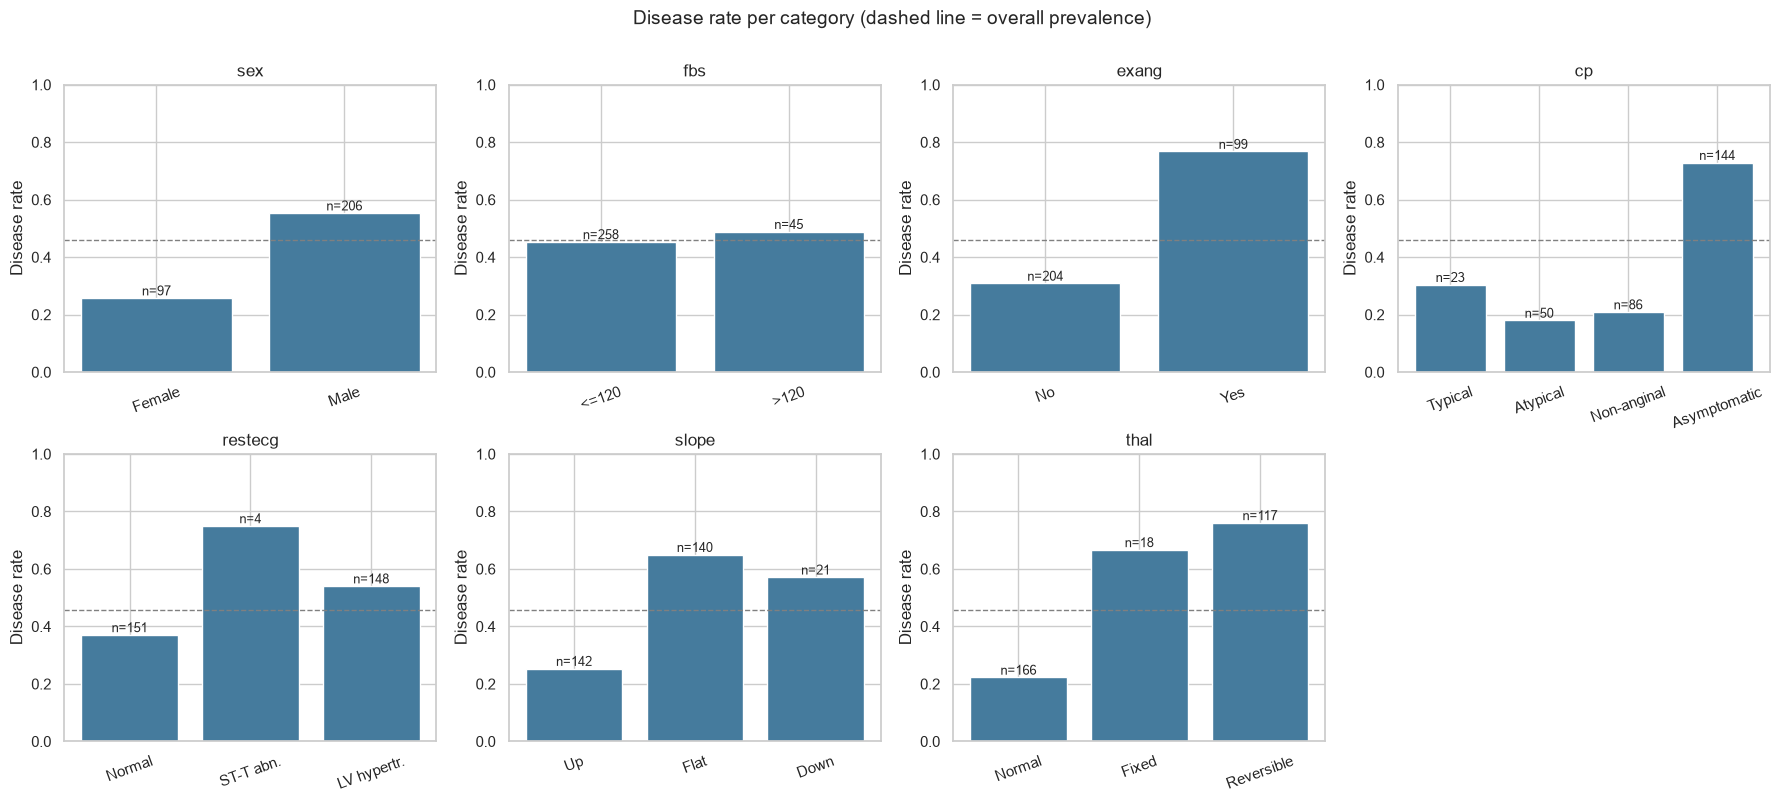

In [9]:
eda.plot_categorical_disease_rate(clean);

## 7. Correlations
Spearman rank correlation is used because several attributes are ordinal / binary and `oldpeak`, `chol` are skewed.

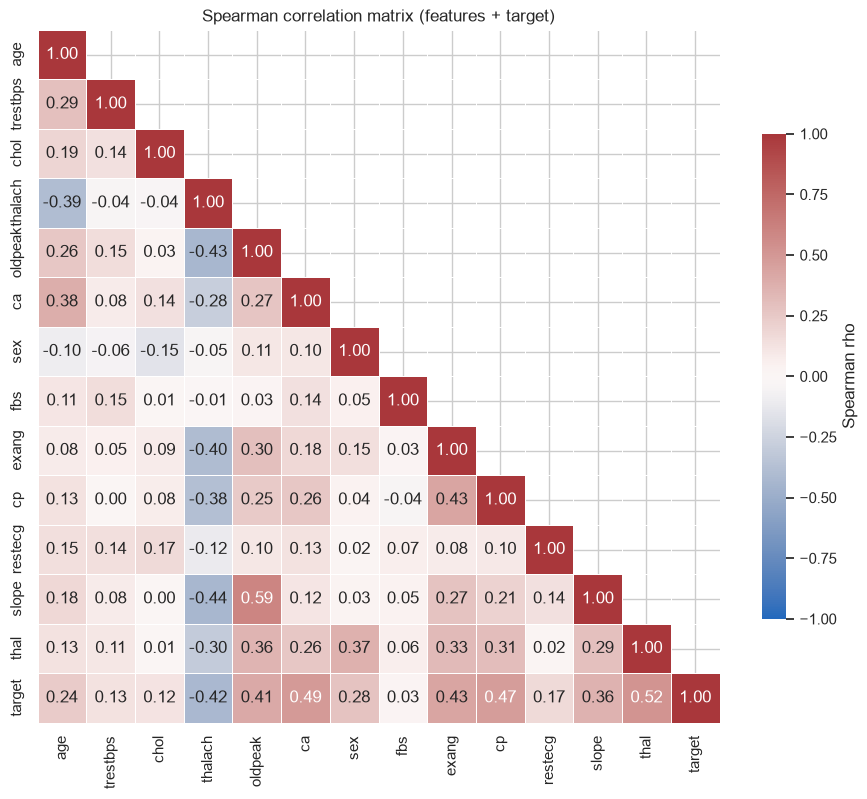

In [10]:
eda.plot_correlation_heatmap(clean);

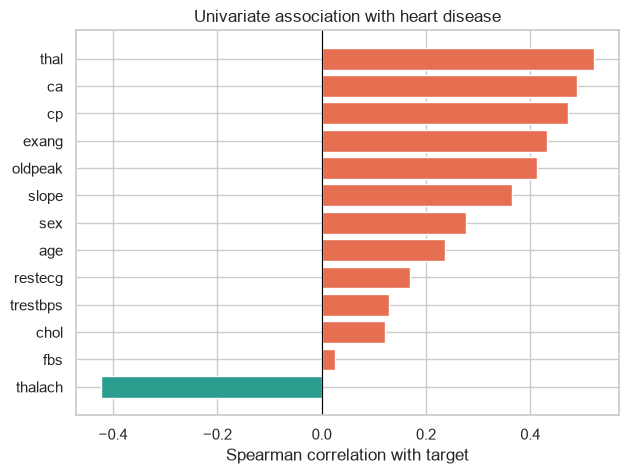

In [11]:
eda.plot_target_correlation(clean);

## 8. Motivation for engineered features
Maximum heart rate naturally declines with age, so the raw `thalach` mixes two effects. Dividing it by the age-predicted maximum (220 - age) gives **`hr_achievement`**, a clinically used measure of chronotropic response. Diseased patients cluster well below the dashed line.

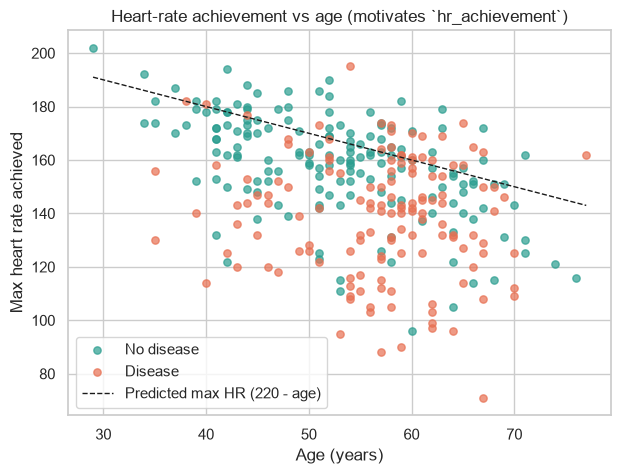

In [12]:
eda.plot_age_hr_scatter(clean);

In [13]:
from heart_disease.features import ClinicalFeatureAdder

engineered = ClinicalFeatureAdder().transform(clean[config.FEATURES]).assign(target=clean[config.TARGET])
engineered.groupby("target")[["hr_achievement", "risk_flag_count"]].mean().rename(index=eda.TARGET_LABELS)

,hr_achievement,risk_flag_count
target,,
No disease,0.95,0.99
Disease,0.85,1.67


## 9. Key findings

* **Strongest signals:** asymptomatic chest pain (`cp=4`), reversible thallium defect (`thal=7`), number of coloured vessels (`ca`), exercise-induced angina (`exang`), ST depression (`oldpeak`) and a *low* maximum heart rate (`thalach`).
* **Weak signals:** cholesterol, fasting blood sugar and resting ECG show little univariate separation - kept, but expected to receive small weights.
* **Data quality:** only 6 missing cells (`ca`: 4, `thal`: 2), no duplicates, no out-of-range values in the Cleveland subset.
* **Encoding decisions:** `cp`, `restecg`, `slope`, `thal` are nominal -> one-hot; `sex`, `fbs`, `exang` are already 0/1; `ca` is an ordered count -> treated as numeric and scaled.
* **Engineered features:** `hr_achievement` and `risk_flag_count` both separate the classes and are added inside the model pipeline.

In [14]:
config.PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
clean.to_csv(config.CLEAN_DATA_FILE, index=False)
print("Saved cleaned dataset ->", config.CLEAN_DATA_FILE.relative_to(config.PROJECT_ROOT))

Saved cleaned dataset -> data\processed\heart_disease_clean.csv
